# 地磁场测量实验 —— 磁阻传感器方向特性的测量

**原始数据**：表 11-2，传感器平面与磁场方向夹角 $\alpha$（0°–90°，每 10° 一点）与输出电压 $U$。

> 表中 0°、10° 两格先写了 0.122、0.999，后划掉改写为 1.021、1.015。按作废值处理，
> 采用改写后的 1.021、1.015（与 20° 起的 0.988、0.922… 序列连续）。

**物理原理**

磁阻传感器的输出电压正比于磁场**在敏感方向上**的分量。若磁场大小不变、
传感器绕垂直于磁场的轴转动 $\alpha$，则
$$U = U_m\cos\alpha,$$
$\alpha=0^\circ$ 时输出最大，$\alpha=90^\circ$ 时输出为零。本实验即以
$U$–$\alpha$ 曲线检验这一余弦规律。

**处理思路**

1. 10 个数据点原样作图（黑色实心方块），不作平滑。
2. 按纯余弦规律 $U=A\cos\alpha$（单参数，$90^\circ$ 处强制为零）作最小二乘拟合，
   这样检验的是"规律本身"，而不是用额外的相位/偏置参数去迁就数据。
3. 逐点计算残差，检查偏差是随机的还是系统的，据此判断"是否符合余弦规律"。


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.font_manager as fm

# ---------- 字体：英文用 Times New Roman，中文逐字回退到宋体 ----------
_installed = {f.name for f in fm.fontManager.ttflist}
_cjk_candidates = ['SimSun', 'STSong', 'Songti SC', 'Noto Serif SC',
                   'Source Han Serif SC', 'SimHei', 'Microsoft YaHei']
CJK_FONT = next((f for f in _cjk_candidates if f in _installed), 'DejaVu Sans')

# 注意：字体名必须直接写进 font.family 列表，matplotlib 才会逐字回退
rcParams['font.family']        = ['Times New Roman', CJK_FONT, 'DejaVu Sans']
rcParams['mathtext.fontset']   = 'stix'
rcParams['axes.unicode_minus'] = False
rcParams['figure.facecolor']   = 'white'
rcParams['savefig.facecolor']  = 'white'

pd.set_option('display.unicode.east_asian_width', True)

# ---------- 原始数据（表 11-2） ----------
alpha_deg = np.arange(0, 91, 10, dtype=float)      # 夹角 α/(°)
U_V = np.array([1.021, 1.015, 0.988, 0.922, 0.826,  # 输出电压 U/V
                0.715, 0.579, 0.395, 0.230, 0.001])

# ---------- 余弦拟合 U = A·cos α（单参数，过 90° 零点） ----------
n      = len(U_V)
cos_a  = np.cos(np.deg2rad(alpha_deg))
A      = np.sum(U_V * cos_a) / np.sum(cos_a ** 2)   # 最小二乘解
U_hat  = A * cos_a
res    = U_V - U_hat
ss_res = np.sum(res ** 2)
ss_tot = np.sum((U_V - U_V.mean()) ** 2)
r2     = 1 - ss_res / ss_tot
adj_r2 = 1 - (1 - r2) * (n - 1) / (n - 1)           # 残差自由度 n−1（单参数）

s      = np.sqrt(ss_res / (n - 1))
se_A   = s / np.sqrt(np.sum(cos_a ** 2))            # 振幅标准误差
i_max  = np.argmax(np.abs(res))

df = pd.DataFrame({
    '夹角 α/(°)':    alpha_deg.astype(int),
    '测量值 U/(V)':  U_V,
    '拟合值 Û/(V)':  U_hat.round(4),
    '残差 U−Û/(V)':  res.round(4),
    '残差/振幅 (%)': (res / A * 100).round(1),
})
display(df)

print(f'拟合方程 : U = {A:.4f} · cos α   (V)')
print(f'振幅 A   = {A:.4f} ± {se_A:.4f}  V')
print(f'R² = {r2:.5f}    Adj. R² = {adj_r2:.5f}')
print(f'最大偏差 = {res[i_max]:+.4f} V，出现在 α = {alpha_deg[i_max]:.0f}°'
      f'（振幅的 {abs(res[i_max])/A*100:.1f}%）')
print(f'0° 实测 {U_V[0]:.3f} V，90° 实测 {U_V[-1]:.3f} V')


def style_axes(ax):
    """统一坐标轴风格：四边框、刻度朝内、无网格（Origin 默认外观）。"""
    ax.set_xlim(-6, 96)
    ax.set_ylim(-0.06, 1.16)
    ax.set_xticks(np.arange(0, 91, 10))
    ax.set_yticks(np.arange(0.0, 1.01, 0.2))
    ax.tick_params(direction='in', length=4.5, width=0.9,
                   top=True, right=True, labelsize=11, pad=6)
    for sp in ax.spines.values():
        sp.set_linewidth(1.0)
    ax.set_xlabel('夹角 α/(°)', fontsize=14, labelpad=6)
    ax.set_ylabel('输出电压 U/(V)', fontsize=14, labelpad=8)


def add_table_box(ax, rows, col_widths, bbox):
    """Origin 风格信息框：白色底、细灰边框、文字左对齐。"""
    tbl = ax.table(cellText=rows, cellLoc='left',
                   colWidths=col_widths, bbox=bbox)
    tbl.auto_set_font_size(False)
    for cell in tbl.get_celld().values():
        cell.set_edgecolor('#808080')
        cell.set_linewidth(0.6)
        cell.set_facecolor('white')
        cell.get_text().set_fontsize(9.5)
    return tbl


,夹角 α/(°),测量值 U/(V),拟合值 Û/(V),残差 U−Û/(V),残差/振幅 (%)
0,0,1.021,1.0609,-0.0399,-3.8
1,10,1.015,1.0448,-0.0298,-2.8
2,20,0.988,0.9969,-0.0089,-0.8
3,30,0.922,0.9187,0.0033,0.3
4,40,0.826,0.8127,0.0133,1.3
5,50,0.715,0.6819,0.0331,3.1
6,60,0.579,0.5304,0.0486,4.6
7,70,0.395,0.3628,0.0322,3.0
8,80,0.230,0.1842,0.0458,4.3
9,90,0.001,0.0000,0.0010,0.1


拟合方程 : U = 1.0609 · cos α   (V)
振幅 A   = 1.0609 ± 0.0144  V
R² = 0.99195    Adj. R² = 0.99195
最大偏差 = +0.0486 V，出现在 α = 60°（振幅的 4.6%）
0° 实测 1.021 V，90° 实测 0.001 V


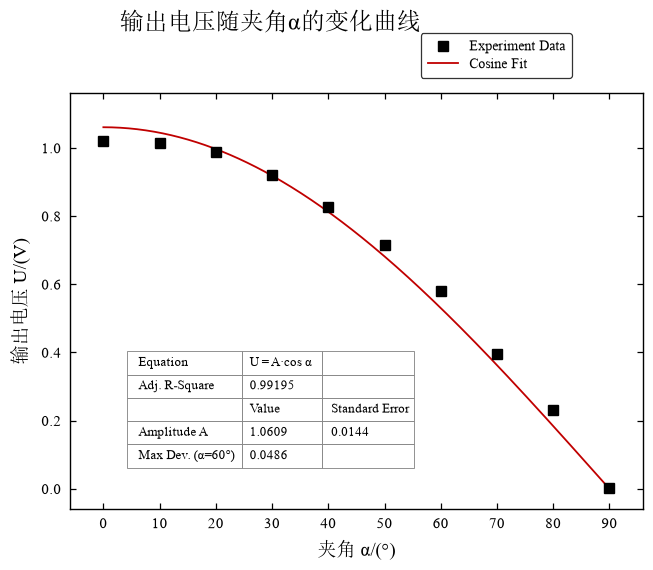

In [2]:
# ================= 图 2：散点 + 余弦拟合（Origin 版式） =================
fig, ax = plt.subplots(figsize=(7.4, 5.4))

# 实验点（黑色实心方块）
# 图例文字用英文：中文标签在内联预览的图例里可能丢字（不影响存图）
ax.plot(alpha_deg, U_V, linestyle='none', marker='s', markersize=6.5,
        color='black', label='Experiment Data', zorder=3)

# 余弦拟合曲线
xx = np.linspace(0, 90, 300)
ax.plot(xx, A * np.cos(np.deg2rad(xx)), color='#C00000', linewidth=1.3,
        label='Cosine Fit', zorder=2)

style_axes(ax)
ax.set_title('输出电压随夹角α的变化曲线', fontsize=17, x=0.35, pad=46)

leg = ax.legend(loc='lower left', bbox_to_anchor=(0.60, 1.02),
                fontsize=10, frameon=True, borderpad=0.5,
                labelspacing=0.35, handlelength=2.2)
leg.get_frame().set_linewidth(0.9)
leg.get_frame().set_edgecolor('black')

# ---- Origin 风格拟合结果框 ----
add_table_box(ax,
              rows=[['Equation',      'U = A·cos α',  ''],
                    ['Adj. R-Square', f'{adj_r2:.5f}', ''],
                    ['',              'Value',        'Standard Error'],
                    ['Amplitude A',   f'{A:.4f}',     f'{se_A:.4f}'],
                    [f'Max Dev. (α={alpha_deg[i_max]:.0f}°)', f'{abs(res[i_max]):.4f}', '']],
              col_widths=[0.40, 0.28, 0.32],
              bbox=[0.10, 0.10, 0.50, 0.28])

plt.savefig('图2_磁阻传感器_方向特性_余弦拟合.png', dpi=300, bbox_inches='tight')
plt.show()


## 结果分析

**1. 端点与总体趋势符合余弦规律**

$\alpha=0^\circ$ 时输出最大（1.021 V），$\alpha=90^\circ$ 时降为 0.001 V，
0°–90° 内单调减小且曲线下弯，与 $U=U_m\cos\alpha$ 的形状一致。
按单参数余弦 $U=A\cos\alpha$ 拟合得
$$A = 1.0609 \pm 0.0144\ \mathrm{V},\qquad \mathrm{Adj.}\ R^2 = 0.99195 .$$

**2. 中段存在系统性正偏差**

残差并不是随机分布在零附近：从 30° 到 80°，实测值系统性地高于拟合曲线，
最大正偏差出现在 60°：$+0.049$ V，约为振幅的 4.6%。若直接取实测
$U(0)=1.021$ V 作理想余弦 $U=1.021\cos\alpha$，60° 处偏差达 $+0.067$ V（6.7%）。
拟合振幅（1.061 V）比实测最大读数（1.021 V）高 3.9%，也说明中段读数整体偏"鼓"。

**3. 误差来源**

- **传感器响应的非线性/饱和**：磁阻电桥在较强磁场下灵敏度下降，输出被压缩；
  这会使中段（磁场分量较大处）读数相对偏高，正好对应残差的形状。
- **角度读数误差**：转盘刻度与传感器敏感轴的 0° 对准、转动时的回差。
- **磁场条件**：线圈磁场在样品处不完全均匀，转轴与磁场方向未严格垂直。
- 90° 处残余 0.001 V，对应零点漂移与地磁本底，可忽略。

**4. 结论**

输出电压随夹角的变化曲线在**形状和端点上与余弦规律一致**，可近似写作
$U \approx 1.06\cos\alpha$（V）；但 30°–80° 区间存在约 5% 的系统性偏差，
严格地说只是"基本符合"余弦规律。若要求更高精度，应先用表 11-1 的
$U$–$B$ 校准曲线把各角度电压换算成磁场分量，再与 $\cos\alpha$ 比较，
以分离传感器非线性与方向特性本身。
